# Parallel QuickSort project 

this presents a first draft of our work, still working on improving the experiments and conclusions.

## 2. Experimental setup

- **Machine:** Laptop with an Intel Core i5-8265U CPU @ 1.60 GHz, 4 physical cores and 8 logical processors. RAM: 16Go/ 8go wsl
- **OS / environment:** Windows 10 Pro (version 10.0.26200), running Ubuntu 22.04 under WSL2 with Linux kernel 6.18.54.1-microsoft-standard-WSL2.
- **Compiler:** GCC 11.4.0.

In [2]:
!mamba install pandas seaborn scipy

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 11.860 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.0.6    np23py313h124dbc7_0  emscripten-forge-4x
+ patsy          1.0.3    py313h1804a44_0      emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
+ seaborn        0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base   0.13.2   pyhd8ed1ab_3         conda-forge
+ statsmodels    0.15.0   np23py313h07ed413_0  emscripten-forge-4x
- pip            26.2.1   pyh145f28c_0         conda-forge


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")

In [35]:
COLUMNS = {"Size", "Type", "Time"}


def load_measurements(csv_path, required_columns=COLUMNS):

    csv_path = Path(csv_path)
    

    data = pd.read_csv(csv_path, skipinitialspace=True)
    data.columns = data.columns.astype(str).str.strip()

  

    data = data.copy()
    data["Type"] = data["Type"].astype(str).str.strip().str.strip('"')
    data["Size"] = pd.to_numeric(data["Size"], errors="coerce")
    data["Time"] = pd.to_numeric(data["Time"], errors="coerce")

   
    data["rep"] = data.groupby(["Size", "Type"], observed=True).cumcount() + 1
    return data


def confidence_interval_95(values):
    values = pd.Series(values).dropna()
    n = len(values)
    if n < 2:
        return np.nan
    return stats.t.ppf(0.975, df=n - 1) * stats.sem(values)


def summarize_measurements(data):
    required = {"Size", "Type", "Time"}
  
    summary = (
        data.groupby(["Size", "Type"], observed=True)["Time"]
        .agg(Mean="mean", Median="median", Std="std", Runs="count")
        .reset_index()
    )

    ci = (
        data.groupby(["Size", "Type"], observed=True)["Time"]
        .apply(confidence_interval_95)
        .rename("CI95")
        .reset_index()
    )
    summary = summary.merge(ci, on=["Size", "Type"], how="left")
    return summary.sort_values(["Size", "Type"]).reset_index(drop=True)


def plot_measurements(summary, order=None, colors=None, title=None, ax=None):

    required = {"Size", "Type", "Mean", "CI95"}
    
    labels = list(summary["Type"].dropna().unique())
    if order is None:
        order = labels
    else:
        order = list(order) + [label for label in labels if label not in order]

    if colors is None:
        colors = {}

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5.5))

    for label in order:
        subset = summary[summary["Type"] == label].sort_values("Size")
        if subset.empty:
            continue

        yerr = subset["CI95"].fillna(0)
        ax.errorbar(
            subset["Size"],
            subset["Mean"],
            yerr=yerr,
            label=label,
            color=colors.get(label),
            marker="o",
            linewidth=2,
            capsize=4,
        )

    ax.set_xscale("log") 

    ax.set_xlabel("Array Size (N)")
    ax.set_ylabel("Execution Time (seconds)")
    ax.set_title(title or "Execution Time vs. Input Size")
    ax.legend(title="Implementation")
    ax.figure.tight_layout()
    return ax


## 3. Redoing the first experiment

We re run the same script on the original repository; We parsed the results in the measurments.csv files that will be found in the data directory.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")

ORDER = ["Sequential", "Parallel", "Built-in"]
COLORS = {"Sequential": "#1f77b4", "Parallel": "#d62728", "Built-in": "#2ca02c"}


df = pd.read_csv("measurements_1910.csv", skipinitialspace=True)
df.columns = df.columns.str.strip()
df["Type"] = df["Type"].astype(str).str.strip().str.strip('"')

df["Type"] = pd.Categorical(df["Type"], categories=ORDER, ordered=True)
df["rep"] = df.groupby(["Size", "Type"], observed=True).cumcount() + 1

df.head(6)

Loaded 75 measurements successfully.


,Size,Type,Time,rep
0,100,Sequential,0.000018,1
1,100,Parallel,0.036879,1
2,100,Built-in,0.000017,1
3,100,Sequential,0.000019,2
4,100,Parallel,0.036896,2
5,100,Built-in,0.000017,2


In [39]:

CSV_PATH = Path("measurements_1910.csv")


IMPLEMENTATION_ORDER = ["Sequential", "Parallel", "Built-in"]
IMPLEMENTATION_COLORS = {
    "Sequential": "#1f77b4",
    "Parallel": "#d62728",
    "Built-in": "#2ca02c",
}

df = load_measurements(CSV_PATH)
summary = summarize_measurements(df)

display(df.head())
display(summary)

,Size,Type,Time,rep
0,100,Sequential,0.000018,1
1,100,Parallel,0.036879,1
2,100,Built-in,0.000017,1
3,100,Sequential,0.000019,2
4,100,Parallel,0.036896,2


,Size,Type,Mean,Median,Std,Runs,CI95
0,100,Built-in,0.000017,0.000017,0.000000e+00,5,0.000000e+00
1,100,Parallel,0.034968,0.034812,1.886297e-03,5,2.342147e-03
2,100,Sequential,0.000018,0.000018,4.472136e-07,5,5.552890e-07
3,1000,Built-in,0.000243,0.000238,1.018332e-05,5,1.264426e-05
4,1000,Parallel,0.101224,0.100145,4.814921e-03,5,5.978515e-03
5,1000,Sequential,0.000246,0.000238,1.288410e-05,5,1.599772e-05
6,10000,Built-in,0.002591,0.002581,1.234330e-04,5,1.532623e-04
7,10000,Parallel,0.195868,0.189199,1.818202e-02,5,2.257596e-02
8,10000,Sequential,0.002931,0.002998,2.251548e-04,5,2.795667e-04
9,100000,Built-in,0.033280,0.032398,3.171526e-03,5,3.937970e-03


##  Aggregation and Methodology

To analyze benchmarking results, We need to aggregate results accross different repetitions using:

1. **Mean:**
2. **Median:**
3. **95% Confidence Interval ($\text{CI}_{95\%}$):** 
     - Because $n = 5$ is very small, we  use the **Student-$t$ distribution** with $df = n - 1 = 4$ degrees of freedom instead of a standard normal $Z$-score (1.96). 
   - For $df = 4$, $t^* \approx 2.776$, which appropriately penalizes the low sample size.
  

## 3 Results

### Time as a function of the array size

Both axes are logarithmic, because the sizes span four orders of magnitude. Each small dot is one measurement; the line with error bars is the mean with its 95 % confidence interval.

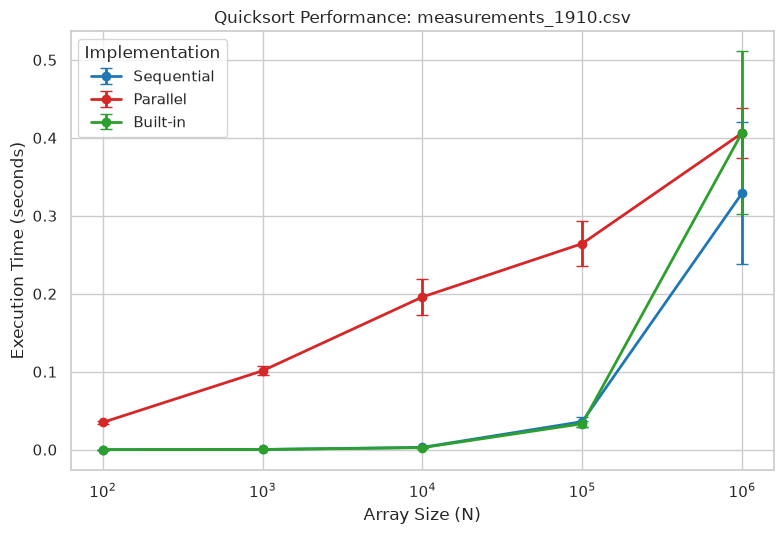

In [40]:
ax = plot_measurements(
    summary,
    order=IMPLEMENTATION_ORDER,
    colors=IMPLEMENTATION_COLORS,
    title=f"Quicksort Performance: {CSV_PATH.name}",
)
plt.show()

## Explanation of the Results

The results show that the parallel implementation is slower than the sequential and built-in implementations for all tested array sizes. For small inputs, the overhead of parallelization likely outweighs its benefits. As the input size increases, execution times rise for all implementations, and their performance becomes more comparable at \\(N = 10^6\\), although the sequential implementation remains the fastest.

The error bars are generally small but widen for the largest input, indicating greater variability in the measurements. Their overlap suggests that the observed differences may not be statistically significant. Overall, the parallel implementation does not demonstrate a performance advantage within the tested range.

Differences from the original experiment may be due to variations in hardware, operating system etc.

## Increasing the array size :
We re run the experiment again with sizes values 10**7 and 10**8

In [29]:

CSV_PATH = Path("measurements_2126.csv")


df = load_measurements(CSV_PATH)
summary = summarize_measurements(df)

display(df.head())
display(summary)

,Size,Type,Time,rep
0,100,Sequential,0.000009,1
1,100,Parallel,0.025419,1
2,100,Built-in,0.000010,1
3,100,Sequential,0.000010,2
4,100,Parallel,0.017201,2


,Size,Type,Mean,Median,Std,Runs,CI95
0,100,Built-in,0.000009,0.000008,8.944272e-07,5,0.000001
1,100,Parallel,0.016717,0.016070,5.387008e-03,5,0.006689
2,100,Sequential,0.000009,0.000009,8.366600e-07,5,0.000001
3,1000,Built-in,0.000193,0.000146,1.164375e-04,5,0.000145
4,1000,Parallel,0.049494,0.046861,7.406103e-03,5,0.009196
5,1000,Sequential,0.000118,0.000112,2.111161e-05,5,0.000026
6,10000,Built-in,0.001443,0.001410,1.252949e-04,5,0.000156
7,10000,Parallel,0.085392,0.086712,6.122997e-03,5,0.007603
8,10000,Sequential,0.001337,0.001326,2.705919e-05,5,0.000034
9,100000,Built-in,0.016117,0.016019,3.528289e-04,5,0.000438


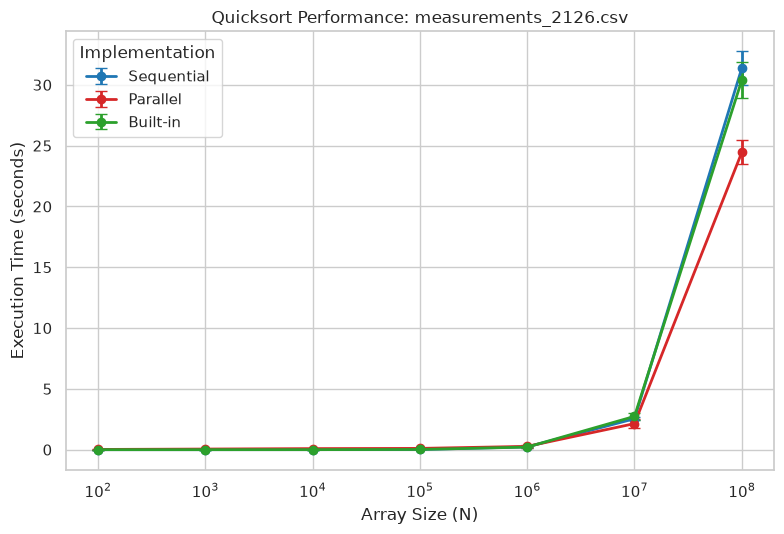

In [36]:
ax = plot_measurements(
    summary,
    order=IMPLEMENTATION_ORDER,
    colors=IMPLEMENTATION_COLORS,
    title=f"Quicksort Performance: {CSV_PATH.name}",
)
plt.show()

At 10**8 we can finally see that the parallel takes less execution time than others, However we might need results for bigger sizes.

## 4. Improved experiment

The first experiment had weaknesses in its design: only 5 repetitions, sizes up to 10⁶ only, and a fixed order (sizes ascending, repetitions back to back). We kept the **same binary** and changed only the run script (`scripts/run_improved.sh`):

| | Original | Improved |
|---|---|---|
| Repetitions | 5 | 30 up to 10⁶, then 15, 10, 5, 3 for 10⁷, 2·10⁷, 10⁸, 2·10⁸ (big runs take minutes) |
| Sizes | 10² to 10⁶ | 10² to 2·10⁸ (with extra points at 2·10⁷) |
| Run order | ascending, back to back | **fully shuffled** (`shuf`) |
| Input array | same array if two runs start in the same second (`srand(time(NULL))`) | `sleep 1` between runs |

183 runs in total.

In [41]:
CSV = "measurements_0151.csv"         
d = pd.read_csv(CSV, skipinitialspace=True)
d["Type"] = d["Type"].str.strip().str.strip('"')
d["run"] = np.arange(len(d)) // 3       
w = d.pivot(index="run", columns="Type", values="Time")
w["Size"] = d.groupby("run")["Size"].first().astype(int)
w["order"] = w.index                    
w["speedup"] = w["Sequential"] / w["Parallel"]
print(len(w), "runs;", "runs per size:", w.groupby("Size").size().to_dict())

183 runs; runs per size: {100: 30, 1000: 30, 10000: 30, 100000: 30, 1000000: 30, 10000000: 15, 20000000: 10, 100000000: 5, 200000000: 3}


Type,Built-in,Parallel,Sequential
Size,,,
100,0.0000,0.0459,0.0000
1000,0.0003,0.1137,0.0004
10000,0.0028,0.1992,0.0057
100000,0.0281,0.2163,0.0437
1000000,0.3609,0.3542,0.4126
10000000,3.2493,2.2830,3.2845
20000000,7.0346,4.8202,6.9408
100000000,41.2511,25.3714,36.4155
200000000,85.8783,52.4963,86.0109


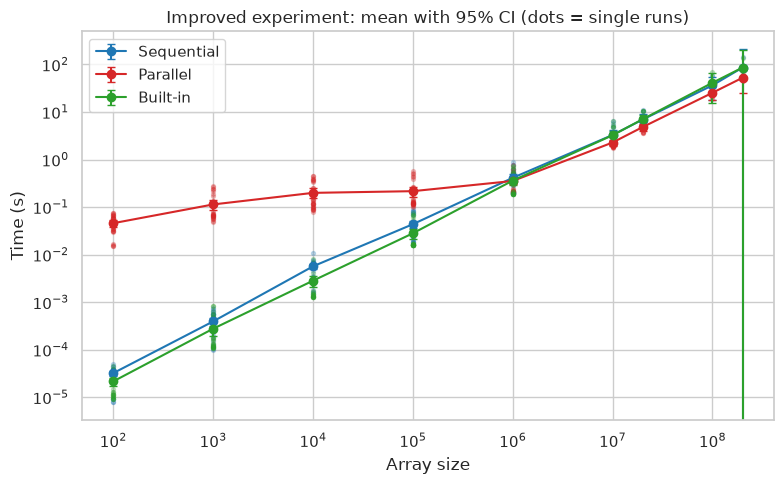

In [42]:
def ci95(x):
    x = np.asarray(x); n = len(x)
    return stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan

summ = (d.groupby(["Size", "Type"])["Time"].agg(n="count", mean="mean", ci=ci95).reset_index())
display(summ.pivot(index="Size", columns="Type", values="mean").round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for t in ["Sequential", "Parallel", "Built-in"]:
    s = summ[summ.Type == t]
    ax.scatter(d[d.Type == t].Size, d[d.Type == t].Time, s=8, alpha=0.25, color=COLORS[t])
    ax.errorbar(s.Size, s["mean"], yerr=s.ci, marker="o", capsize=3, color=COLORS[t], label=t)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Array size"); ax.set_ylabel("Time (s)"); ax.legend()
ax.set_title("Improved experiment: mean with 95% CI (dots = single runs)")
plt.tight_layout(); plt.show()

similarly to the original experiment, the curves cross: the parallel version is far slower for small arrays and slightly faster from about 10⁶–10⁷. But the single runs (dots) are very spread out for large sizes, much more than in the first experiment. Before computing a speedup, we need to understand this noise.

### 4.2 Was the machine stable during the experiment?

Thanks to the shuffled order we can plot each run against its **position in the experiment**. For each implementation and size, time is divided by the fastest time observed (1 = best case), so that all sizes share one axis.

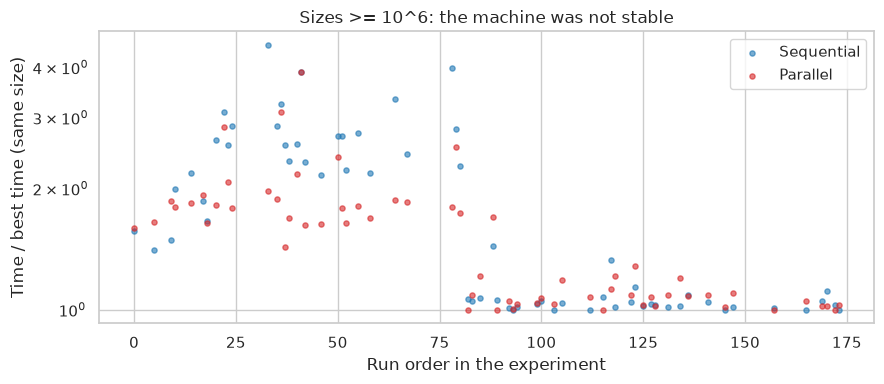

In [43]:
long = d.copy()
long["order"] = long["run"]
long["slowdown"] = long.Time / long.groupby(["Size", "Type"]).Time.transform("min")
big = long[long.Size >= 10**6]

fig, ax = plt.subplots(figsize=(9, 4))
for t in ["Sequential", "Parallel"]:
    b = big[big.Type == t]
    ax.scatter(b.order, b.slowdown, s=14, alpha=0.6, color=COLORS[t], label=t)
ax.set_yscale("log"); ax.set_xlabel("Run order in the experiment"); ax.set_ylabel("Time / best time (same size)")
ax.set_title("Sizes >= 10^6: the machine was not stable"); ax.legend()
plt.tight_layout(); plt.show()

The first part of the experiment is clearly **slower**, then the times drop and stay low. Sequential is slowed down by a factor 2 to 2.5, parallel less. Something on the laptop changed during the run (background load, power or thermal state; we cannot tell from the data). Because the order was shuffled, this disturbance is spread over all sizes instead of being mistaken for an effect of size. This is exactly what randomisation protects against. It does, however, inflate the noise, and it affects sequential and parallel differently, so we need to check it does not drive the conclusion.

We locate the change with a simple search for the break point that best splits the run order into two stable levels (sizes ≥ 10⁶, log-times).

In [44]:
b = big[big.Type == "Sequential"].sort_values("order")
y, o = np.log(b.slowdown.values), b.order.values
sse = [((y[:k] - y[:k].mean())**2).sum() + ((y[k:] - y[k:].mean())**2).sum() for k in range(5, len(y) - 5)]
CP = o[5 + int(np.argmin(sse))]
w["regime"] = np.where(w.order < CP, "early (slow)", "late (stable)")
print("break point at run", CP, "->", w.groupby("regime").size().to_dict())

break point at run 82 -> {'early (slow)': 82, 'late (stable)': 101}


### 4.3 Paired speedup

In each run the three implementations sort **the same array** within a few seconds, so we can compute the ratio `T_seq / T_par` per run, which cancels most of the input variability. We average the **logarithms** (geometric mean of a ratio) and give a 95 % Student CI. Above 1 means parallel is faster.

,Size,n,speedup,lo,hi
0,100,30.0,0.001,0.001,0.001
1,1000,30.0,0.003,0.003,0.004
2,10000,30.0,0.031,0.025,0.039
3,100000,30.0,0.214,0.185,0.247
4,1000000,30.0,1.100,0.996,1.214
5,10000000,15.0,1.367,1.231,1.517
6,20000000,10.0,1.387,1.229,1.565
7,100000000,5.0,1.382,1.094,1.746
8,200000000,3.0,1.498,0.642,3.496


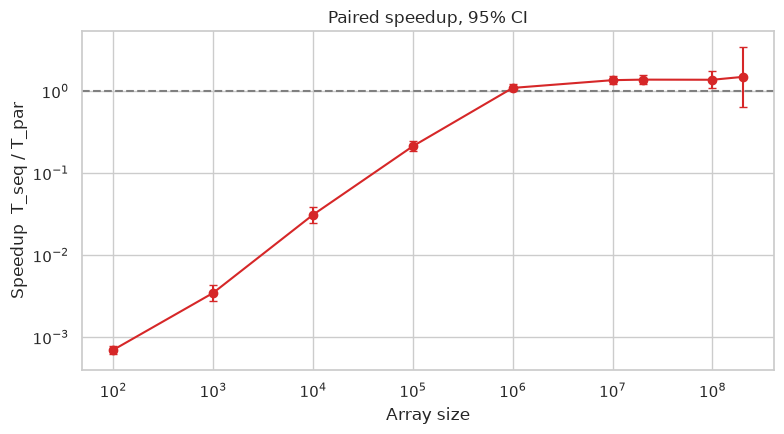

In [45]:
def gm_ci(x):
    l = np.log(np.asarray(x)); n = len(l)
    if n < 2: return pd.Series(dict(n=n, speedup=np.exp(l.mean()), lo=np.nan, hi=np.nan))
    m, se, q = l.mean(), l.std(ddof=1) / np.sqrt(n), stats.t.ppf(0.975, n - 1)
    return pd.Series(dict(n=n, speedup=np.exp(m), lo=np.exp(m - q*se), hi=np.exp(m + q*se)))

sp = w.groupby("Size")["speedup"].apply(gm_ci).unstack().reset_index()
display(sp.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(sp.Size, sp.speedup, yerr=[sp.speedup - sp.lo, sp.hi - sp.speedup], marker="o", capsize=3, color=COLORS["Parallel"])
ax.axhline(1, ls="--", color="gray"); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Array size"); ax.set_ylabel("Speedup  T_seq / T_par"); ax.set_title("Paired speedup, 95% CI")
plt.tight_layout(); plt.show()

 for sizes up to 10⁵ the parallel version is much slower (speedup far below 1, thread overhead). At 10⁶ the CI contains 1. From 10⁷ the CI is above 1: the parallel version is about 1.4 times faster, and this stays roughly constant up to 10⁸. At 2·10⁸ we only have 3 runs, so the interval is far too wide to conclude anything.

## 4.4 Is the speedup robust to the instability?
We recompute the speedup separately for the early (slow) and late (stable) part of the experiment, for large sizes.

,regime,Size,n,speedup,lo,hi
0,early (slow),1000000,18.0,1.240,1.078,1.426
1,early (slow),10000000,5.0,1.617,1.196,2.185
2,early (slow),20000000,4.0,1.606,1.239,2.080
3,early (slow),100000000,2.0,1.589,0.223,11.323
4,early (slow),200000000,1.0,2.218,NaN,NaN
5,late (stable),1000000,12.0,0.919,0.880,0.959
6,late (stable),10000000,10.0,1.256,1.192,1.325
7,late (stable),20000000,6.0,1.258,1.153,1.374
8,late (stable),100000000,3.0,1.260,0.934,1.699
9,late (stable),200000000,2.0,1.230,0.880,1.721


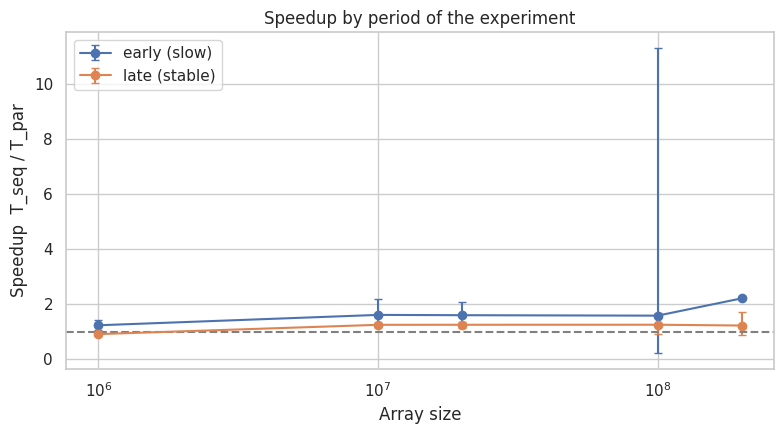

In [7]:
rg = (w[w.Size >= 10**6].groupby(["regime", "Size"])["speedup"].apply(gm_ci).unstack().reset_index())
display(rg.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
for r, g in rg.groupby("regime"):
    ax.errorbar(g.Size, g.speedup, yerr=[g.speedup - g.lo, g.hi - g.speedup], marker="o", capsize=3, label=r)
ax.axhline(1, ls="--", color="gray"); ax.set_xscale("log")
ax.set_xlabel("Array size"); ax.set_ylabel("Speedup  T_seq / T_par"); ax.legend()
ax.set_title("Speedup by period of the experiment")
plt.tight_layout(); plt.show()

The parallel version is faster at 10⁷ and 2·10⁷ elements in both periods, so this conclusion is reliable. However, the size of the gain depends on the machine’s state: about 1.6× in the slow period and about 1.25× in the stable period. At 10⁶ the winner even changes between periods. We therefore trust the stable-period value (≈1.25×) more, while noting it is based on few runs. The 10⁸ and 2·10⁸ results are too uncertain to conclude.

## Conclusion and next steps
- The 's claim is **only true for large arrays**: the parallel quicksort is much slower below 10⁶ elements, comparable around 10⁶, and faster from about 10⁷ elements.
- **Randomising the run order** revealed an instability of the laptop that the fixed order of the original experiment would have mixed up with an effect of the array size.

This first attempt to improve the experiment was not enough to do a trend and extrapolation, to improve this we will try this on other machines and increase the array sizes.